# OE2 · YOLOv11n-seg · FASE A

Se entrena y evalúa YOLOv11n-seg como parte de la comparación de modelos del OE2.

## 1) Comprobar la GPU y conectar Google Drive
Se verifica que haya GPU disponible y se monta Google Drive.

In [1]:
import os
import torch
assert torch.cuda.is_available(), "Activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU (A100)"
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| CUDA", torch.version.cuda)

from google.colab import drive
drive.mount("/content/drive")

GPU: NVIDIA A100-SXM4-40GB | torch 2.11.0+cu130 | CUDA 13.0
Mounted at /content/drive


## 2) Instalar Ultralytics
Se instala una versión fija para que los resultados sean reproducibles.

In [2]:
%pip install -q ultralytics==8.4.113 pycocotools
import ultralytics
print("ultralytics", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 392.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 2.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.113


## 3) Configuración
Se define la semilla y el dataset de entrenamiento.

In [3]:
import json

SEED = 2026

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
DATASET = "data_estratificado1"

DRIVE_OUT = os.path.join(PROYECTO, "resultados", "oe2", "yolov11nseg", f"seed_{SEED}")
REPORT_DIR = os.path.join(DRIVE_OUT, "reportes")
DRIVE_CKPT = os.path.join(DRIVE_OUT, "ckpt")
DATASET_DIR = "/content/datos"
LOCAL = "/content/yolo"
os.makedirs(REPORT_DIR, exist_ok=True)

with open(os.path.join(PROYECTO, DATASET, "origen.json"), encoding="utf-8") as f:
    ORIGEN = json.load(f)
print(f"YOLOv11n-seg | semilla {SEED} | datos {DATASET} ({ORIGEN['entrada']}) {ORIGEN['imagenes']}")
print("Salida:", DRIVE_OUT)

YOLOv11n-seg | semilla 2026 | datos data_estratificado1 (data_curado) {'train': 982, 'valid': 281, 'test': 141}
Salida: /content/drive/MyDrive/tesis-rg6final/resultados/oe2/yolov11nseg/seed_2026


## 4) Copiar el dataset y verificar que no haya imágenes repetidas
Se copia el dataset al disco de Colab y se comprueba con MD5 que ninguna imagen aparezca en más de una partición.

In [4]:
import shutil, hashlib, collections

def md5(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

if not os.path.exists(DATASET_DIR):
    shutil.copytree(os.path.join(PROYECTO, DATASET), DATASET_DIR)

contenido = {}
for parte in ["train", "valid", "test"]:
    with open(os.path.join(DATASET_DIR, parte, "_annotations.coco.json"), encoding="utf-8") as f:
        coco = json.load(f)
    contenido[parte] = {md5(os.path.join(DATASET_DIR, parte, im["file_name"])) for im in coco["images"]}
    por_clase = collections.Counter(a["category_id"] for a in coco["annotations"])
    print(f"{parte:5s}: {len(coco['images'])} fotos | {len(coco['annotations'])} anotaciones | por clase {dict(por_clase)}")
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    repetidas = contenido[a] & contenido[b]
    assert not repetidas, f"FUGA: {len(repetidas)} fotos idénticas entre {a} y {b}. Corrígelo antes de entrenar."
print("Sin fugas entre train/valid/test")

train: 982 fotos | 4445 anotaciones | por clase {1: 2233, 0: 2212}
valid: 281 fotos | 1309 anotaciones | por clase {0: 660, 1: 649}
test : 141 fotos | 667 anotaciones | por clase {0: 349, 1: 318}
Sin fugas entre train/valid/test


## 5) Receta de entrenamiento FASE A
| Parámetro | Valor | Comentario |
|---|---|---|
| Modelo inicial | `yolo11n-seg.pt` (COCO) | *fine-tuning* |
| Épocas / paciencia | 50 / 30 | mismo presupuesto que Detectron2 |
| `imgsz` / `batch` | 1024 / 16 | una foto 4:3 queda en 1024×768, igual que Detectron2 |
| Optimizador | `auto` → **AdamW lr 0.001667** | Ultralytics lo elige solo; por eso `lr0=0.01` no se llega a usar |
| LR final / *weight decay* / calentamiento | `lrf=0.01` coseno / 0.0005 / 3 épocas | |
| Aumento CommonAug A | hsv 0.015/0.4/0.4, rotación ±5°, volteo horizontal 0.5 | el mismo de los tres modelos; lo demás en 0 |
| AMP + TF32 | sí | más rápido en la A100 |

In [5]:
RECETA_FASE_A = dict(
    epochs=50, imgsz=1024, batch=16, workers=8, deterministic=False,
    val=True, conf=0.25, iou=0.70, max_det=300,
    amp=True, plots=True, verbose=True, exist_ok=True, save_period=10,
    overlap_mask=True, mask_ratio=4, retina_masks=False,
    lr0=0.01, lrf=0.01, weight_decay=0.0005, cos_lr=True, warmup_epochs=3.0, patience=30,
)
COMMON_AUG_A = dict(
    augment=True,
    hsv_h=0.015, hsv_s=0.40, hsv_v=0.40,
    degrees=5.0,
    translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    auto_augment=None, erasing=0.0, close_mosaic=0,
)

## 6) Convertir COCO a formato YOLO
Se convierten las anotaciones de train y valid al formato de etiquetas de YOLO.

In [6]:
import yaml
import numpy as np

def linea_yolo(clase, puntos):
    return f"{clase} " + " ".join(f"{x:.6f} {y:.6f}" for x, y in puntos)

def convertir_a_yolo(carpeta_coco, destino):
    shutil.rmtree(destino, ignore_errors=True)
    nombres_por_parte = {}
    for parte in ["train", "valid"]:
        os.makedirs(os.path.join(destino, "images", parte))
        os.makedirs(os.path.join(destino, "labels", parte))
        with open(os.path.join(carpeta_coco, parte, "_annotations.coco.json"), encoding="utf-8") as f:
            coco = json.load(f)
        categorias = sorted(coco["categories"], key=lambda c: c["id"])
        clase_yolo = {c["id"]: i for i, c in enumerate(categorias)}
        nombres_por_parte[parte] = [c["name"] for c in categorias]
        anots = collections.defaultdict(list)
        for a in coco["annotations"]:
            anots[a["image_id"]].append(a)

        for im in coco["images"]:
            shutil.copy2(os.path.join(carpeta_coco, parte, im["file_name"]), os.path.join(destino, "images", parte))
            w, h = im["width"], im["height"]
            lineas = []
            for a in anots[im["id"]]:
                poligonos = [p for p in (a.get("segmentation") or []) if isinstance(p, list) and len(p) >= 6]
                for p in poligonos:
                    pts = np.array(p, dtype=np.float32).reshape(-1, 2)
                    pts[:, 0] = np.clip(pts[:, 0] / w, 0, 1)
                    pts[:, 1] = np.clip(pts[:, 1] / h, 0, 1)
                    if len(pts) > 120:
                        pts = pts[::2]
                    lineas.append(linea_yolo(clase_yolo[a["category_id"]], pts))
                if not poligonos:
                    x, y, bw, bh = a["bbox"]
                    caja = [(x / w, y / h), ((x + bw) / w, y / h), ((x + bw) / w, (y + bh) / h), (x / w, (y + bh) / h)]
                    lineas.append(linea_yolo(clase_yolo[a["category_id"]], np.clip(caja, 0, 1)))
            nombre_txt = im["file_name"].rsplit(".", 1)[0] + ".txt"
            with open(os.path.join(destino, "labels", parte, nombre_txt), "w") as f:
                f.write("".join(l + "\n" for l in lineas))

    assert nombres_por_parte["train"] == nombres_por_parte["valid"], f"Clases distintas: {nombres_por_parte}"
    ruta_yaml = os.path.join(destino, "dataset.yaml")
    with open(ruta_yaml, "w") as f:
        yaml.dump({"path": destino, "train": "images/train", "val": "images/valid",
                   "nc": len(nombres_por_parte["train"]), "names": nombres_por_parte["train"]}, f)
    print(f"Dataset YOLO listo: {destino} | clases {nombres_por_parte['train']}")
    return ruta_yaml

RUTA_YAML = convertir_a_yolo(DATASET_DIR, os.path.join(LOCAL, "dataset"))

Dataset YOLO listo: /content/yolo/dataset | clases ['rg6Bien', 'rg6Mal']


## 7) Entrenar
Se entrena el modelo guardando puntos de control para poder reanudar.

In [7]:
import glob
from ultralytics import YOLO

PESOS = os.path.join(DRIVE_OUT, "yolov11nseg_best.pt")
if os.path.exists(os.path.join(DRIVE_OUT, "TERMINADO.json")):
    print("Esta semilla ya terminó de entrenar: se salta.")
else:
    torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

    pesos_local = os.path.join(LOCAL, "runs", "train", "weights")
    reanudar = os.path.exists(os.path.join(DRIVE_CKPT, "last.pt"))
    if reanudar:
        os.makedirs(pesos_local, exist_ok=True)
        for archivo in ["last.pt", "best.pt"]:
            if os.path.exists(os.path.join(DRIVE_CKPT, archivo)):
                shutil.copy2(os.path.join(DRIVE_CKPT, archivo), pesos_local)
        print("REANUDO desde", DRIVE_CKPT)
        modelo = YOLO(os.path.join(pesos_local, "last.pt"))
    else:
        modelo = YOLO("yolo11n-seg.pt")

    def copiar_a_drive(trainer):
        os.makedirs(DRIVE_CKPT, exist_ok=True)
        for ruta in (trainer.last, trainer.best, getattr(trainer, "csv", None)):
            if ruta and os.path.exists(ruta):
                shutil.copy2(ruta, DRIVE_CKPT)
    modelo.add_callback("on_model_save", copiar_a_drive)

    if reanudar:
        modelo.train(resume=True)
    else:
        modelo.train(data=RUTA_YAML, seed=SEED, device="0", project=os.path.join(LOCAL, "runs"), name="train",
                     **RECETA_FASE_A, **COMMON_AUG_A)

    best = str(modelo.trainer.best)
    assert os.path.exists(best), "No se encontró best.pt"
    shutil.copy2(best, PESOS)
    shutil.copy2(best, os.path.join(DRIVE_OUT, "best.pt"))
    carpeta_art = os.path.join(DRIVE_OUT, "artefactos", "entrenamiento")
    os.makedirs(carpeta_art, exist_ok=True)
    for ruta in glob.glob(os.path.join(LOCAL, "runs", "train", "*")):
        if os.path.basename(ruta) in ("results.csv", "results.png", "args.yaml"):
            shutil.copy2(ruta, carpeta_art)

    acumulacion = max(round(64 / RECETA_FASE_A["batch"]), 1)
    manifiesto = {"arch": "YOLOv11n-seg", "profile": "A100_MAX", "seed": SEED, "dataset": DATASET,
                  "huella_datos": ORIGEN["huella"], "imgsz": RECETA_FASE_A["imgsz"], "batch": RECETA_FASE_A["batch"],
                  "epochs": RECETA_FASE_A["epochs"], "accumulate": acumulacion,
                  "lote_nominal_optimizador": RECETA_FASE_A["batch"] * acumulacion, "deterministic": False,
                  "workers": RECETA_FASE_A["workers"], "lr0": RECETA_FASE_A["lr0"], "tf32": True, "amp": True,
                  "reanudado": reanudar, "torch": torch.__version__, "ultralytics": ultralytics.__version__,
                  "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0), "best": PESOS}
    for destino in (DRIVE_OUT, carpeta_art):
        with open(os.path.join(destino, "run_manifest.json"), "w") as f:
            json.dump(manifiesto, f, indent=2)
    with open(os.path.join(DRIVE_OUT, "TERMINADO.json"), "w") as f:
        json.dump({"best": PESOS}, f)
    print("Entrenamiento terminado. Pesos:", PESOS)

New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.113 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.25, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo/dataset/dataset.yaml, degrees=5.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

## 8) Evaluación en test
Se evalúa el modelo en el test con COCOeval (mAP de caja y de máscara).

In [8]:
import io, contextlib
import cv2
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util

GT_JSON = os.path.join(DATASET_DIR, "test", "_annotations.coco.json")
with open(GT_JSON, encoding="utf-8") as f:
    coco_test = json.load(f)
id_categoria = {i: c["id"] for i, c in enumerate(sorted(coco_test["categories"], key=lambda c: c["id"]))}

modelo = YOLO(PESOS)
predicciones = []
for im in coco_test["images"]:
    img = cv2.imread(os.path.join(DATASET_DIR, "test", im["file_name"]), cv2.IMREAD_COLOR)
    r = modelo.predict(img, imgsz=1024, conf=0.001, iou=0.70, max_det=300, device="0",
                       retina_masks=True, verbose=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        continue
    cajas = r.boxes.xyxy.cpu().numpy()
    scores = r.boxes.conf.cpu().numpy()
    clases = r.boxes.cls.cpu().numpy().astype(int)
    mascaras = r.masks.data.cpu().numpy()
    H, W = im["height"], im["width"]
    for k in range(len(cajas)):
        x1, y1, x2, y2 = [float(c) for c in cajas[k]]
        m = mascaras[k]
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR)
        rle = mask_util.encode(np.asfortranarray((m > 0.5).astype(np.uint8)))
        rle["counts"] = rle["counts"].decode("ascii")
        predicciones.append({"image_id": im["id"], "category_id": id_categoria[int(clases[k])],
                             "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(scores[k]), "segmentation": rle})

carpeta_pred = os.path.join(DRIVE_OUT, "artefactos", "predicciones_test")
os.makedirs(carpeta_pred, exist_ok=True)
PRED_JSON = os.path.join(carpeta_pred, "coco_instances_results.json")
with open(PRED_JSON, "w") as f:
    json.dump(predicciones, f)
print(f"{len(predicciones)} predicciones en {len(coco_test['images'])} fotos")

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(GT_JSON)
    coco_dt = coco_gt.loadRes(PRED_JSON)

def coco_ap(tipo, categoria=None):
    ev = COCOeval(coco_gt, coco_dt, iouType=tipo)
    if categoria is not None:
        ev.params.catIds = [categoria]
    with contextlib.redirect_stdout(io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"AP": 100 * float(ev.stats[0]), "AP50": 100 * float(ev.stats[1]), "AP75": 100 * float(ev.stats[2])}

bbox, segm = coco_ap("bbox"), coco_ap("segm")
cats = coco_gt.loadCats(coco_gt.getCatIds())
por_clase = {tipo: {c["name"]: coco_ap(tipo, c["id"]) for c in cats} for tipo in ["bbox", "segm"]}
promedio = {f"avg_{tipo}": {k: float(np.mean([v[k] for v in por_clase[tipo].values()])) for k in ["AP", "AP50", "AP75"]}
            for tipo in ["bbox", "segm"]}
ruta_por_clase = os.path.join(REPORT_DIR, "obj2_yolov11_phaseA_per_class_ap.json")
with open(ruta_por_clase, "w") as f:
    json.dump({**por_clase, **promedio}, f, indent=2)

import csv

def guardar_reporte(fila):
    ruta_json = os.path.join(REPORT_DIR, "obj2_results_all_models.json")
    filas = []
    if os.path.exists(ruta_json):
        with open(ruta_json) as f:
            filas = json.load(f)
    filas = [r for r in filas if r.get("arch") != fila["arch"]] + [fila]
    with open(ruta_json, "w") as f:
        json.dump(filas, f, indent=2)
    columnas = list(dict.fromkeys(k for r in filas for k in r))
    with open(os.path.join(REPORT_DIR, "obj2_results_all_models.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=columnas)
        w.writeheader()
        for r in filas:
            w.writerow({k: r.get(k, "") for k in columnas})
    print("Reporte guardado:", ruta_json)

fila = {"arch": "YOLOv11-Seg", "phase": "A",
        "map_bbox_50_95": round(bbox["AP"], 6), "ap50_bbox": round(bbox["AP50"], 6), "ap75_bbox": round(bbox["AP75"], 6),
        "map_segm_50_95": round(segm["AP"], 6), "ap50_segm": round(segm["AP50"], 6), "ap75_segm": round(segm["AP75"], 6),
        "model_size_mb": round(os.path.getsize(PESOS) / 2**20, 3),
        "params_millones": round(sum(p.numel() for p in modelo.model.parameters()) / 1e6, 3),
        "weights": PESOS, "dataset": DATASET, "pred_json": PRED_JSON, "per_class_file": ruta_por_clase,
        "score_thresh_test": 0.001, "max_det": 300, "evaluator": "pycocotools", "ap_scale": "0-100",
        "torch": torch.__version__, "framework": f"ultralytics {ultralytics.__version__}",
        "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0), "seed": SEED, "profile": "A100_MAX"}
guardar_reporte(fila)

print(f"\nTEST · YOLOv11n-seg · semilla {SEED}")
print(f"  mAP50-95 máscara: {segm['AP']:.2f} | AP50 {segm['AP50']:.2f} | AP75 {segm['AP75']:.2f}")
print(f"  mAP50-95 caja   : {bbox['AP']:.2f} | AP50 {bbox['AP50']:.2f} | AP75 {bbox['AP75']:.2f}")
print("  AP máscara por clase:", {k: round(v["AP"], 2) for k, v in por_clase["segm"].items()})

2140 predicciones en 141 fotos
Reporte guardado: /content/drive/MyDrive/tesis-rg6final/resultados/oe2/yolov11nseg/seed_2026/reportes/obj2_results_all_models.json

TEST · YOLOv11n-seg · semilla 2026
  mAP50-95 máscara: 60.68 | AP50 95.26 | AP75 72.30
  mAP50-95 caja   : 70.32 | AP50 95.95 | AP75 86.04
  AP máscara por clase: {'rg6Bien': 61.5, 'rg6Mal': 59.85}


## 9) Matriz de confusión (umbral 0.25)
Se calcula la matriz de confusión a partir de las predicciones del test.

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


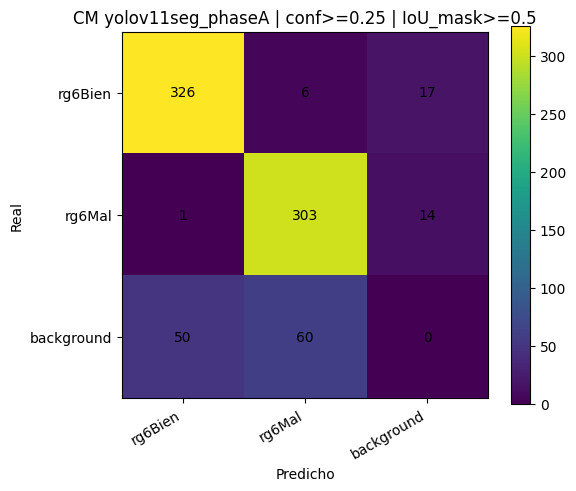

Precisión por clase: {'rg6Bien': np.float64(0.8647), 'rg6Mal': np.float64(0.8211)}
Recall por clase:    {'rg6Bien': np.float64(0.9341), 'rg6Mal': np.float64(0.9528)}


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from pycocotools import mask as mask_util

def matriz_confusion(tag, pred_json, gt_json, out_dir, conf=0.25, iou_min=0.5):
    os.makedirs(out_dir, exist_ok=True)
    coco = COCO(gt_json)
    cats = sorted(coco.loadCats(coco.getCatIds()), key=lambda c: c["id"])
    idx_de = {c["id"]: i for i, c in enumerate(cats)}
    nombres = [c["name"] for c in cats]
    C = len(cats)
    with open(pred_json) as f:
        preds = [p for p in json.load(f) if p["score"] >= conf and "segmentation" in p]
    por_img = {}
    for p in preds:
        por_img.setdefault(p["image_id"], []).append(p)

    cm = np.zeros((C + 1, C + 1), dtype=np.int64)
    for img_id in coco.getImgIds():
        anots = [a for a in coco.loadAnns(coco.getAnnIds(imgIds=[img_id])) if not a.get("iscrowd", 0)]
        reales = [(idx_de[a["category_id"]], coco.annToMask(a).astype(bool)) for a in anots]
        usados = set()
        for p in sorted(por_img.get(img_id, []), key=lambda p: -p["score"]):
            clase_p = idx_de[p["category_id"]]
            mascara_p = mask_util.decode(p["segmentation"]).astype(bool)
            mejor, mejor_iou = -1, 0.0
            for k, (_, mascara_r) in enumerate(reales):
                if k in usados:
                    continue
                inter = np.logical_and(mascara_p, mascara_r).sum()
                if inter == 0:
                    continue
                iou = inter / float(np.logical_or(mascara_p, mascara_r).sum())
                if iou > mejor_iou:
                    mejor_iou, mejor = iou, k
            if mejor >= 0 and mejor_iou >= iou_min:
                usados.add(mejor)
                cm[reales[mejor][0], clase_p] += 1
            else:
                cm[C, clase_p] += 1
        for k, (clase_r, _) in enumerate(reales):
            if k not in usados:
                cm[clase_r, C] += 1

    etiquetas = nombres + ["background"]
    np.savetxt(os.path.join(out_dir, "confusion_matrix.csv"), cm, fmt="%d", delimiter=",")
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm)
    ax.set_xticks(range(C + 1)); ax.set_yticks(range(C + 1))
    ax.set_xticklabels(etiquetas, rotation=30, ha="right"); ax.set_yticklabels(etiquetas)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    ax.set_title(f"CM {tag} | conf>={conf} | IoU_mask>={iou_min}")
    for i in range(C + 1):
        for j in range(C + 1):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "confusion_matrix.png"), dpi=200)
    plt.show()

    precision = {nombres[k]: round(cm[k, k] / max(cm[:, k].sum(), 1), 4) for k in range(C)}
    recall = {nombres[k]: round(cm[k, k] / max(cm[k, :].sum(), 1), 4) for k in range(C)}
    with open(os.path.join(out_dir, "confusion_summary.json"), "w") as f:
        json.dump({"tag": tag, "conf": conf, "iou_mask": iou_min, "labels": etiquetas, "cm": cm.tolist(),
                   "precision_por_clase": precision, "recall_por_clase": recall,
                   "pred_json": pred_json, "gt_json": gt_json}, f, indent=2, ensure_ascii=False)
    print("Precisión por clase:", precision)
    print("Recall por clase:   ", recall)

matriz_confusion("yolov11seg_phaseA", PRED_JSON, os.path.join(DATASET_DIR, "test", "_annotations.coco.json"),
                 os.path.join(REPORT_DIR, "confusion_" + "yolov11seg_phaseA"))

## 10) Registro de la sesión
Se guarda la semilla, la GPU y la fecha de la ejecución.

In [10]:
import datetime
with open(os.path.join(DRIVE_OUT, "sesion.json"), "w") as f:
    json.dump({"seed": SEED, "dataset": DATASET, "huella_datos": ORIGEN["huella"],
               "gpu": torch.cuda.get_device_name(0),
               "vram_total_gb": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1),
               "fecha_utc": datetime.datetime.now(datetime.timezone.utc).isoformat()}, f, indent=2)

for raiz, _, archivos in os.walk(DRIVE_OUT):
    if "ckpt" in raiz:
        continue
    for a in sorted(archivos):
        ruta = os.path.join(raiz, a)
        print(f"  {os.path.getsize(ruta) / 2**20:8.1f} MB  {os.path.relpath(ruta, DRIVE_OUT)}")

       0.0 MB  TERMINADO.json
       5.8 MB  best.pt
       0.0 MB  run_manifest.json
       0.0 MB  sesion.json
       5.8 MB  yolov11nseg_best.pt
       0.0 MB  reportes/obj2_results_all_models.csv
       0.0 MB  reportes/obj2_results_all_models.json
       0.0 MB  reportes/obj2_yolov11_phaseA_per_class_ap.json
       0.0 MB  reportes/confusion_yolov11seg_phaseA/confusion_matrix.csv
       0.1 MB  reportes/confusion_yolov11seg_phaseA/confusion_matrix.png
       0.0 MB  reportes/confusion_yolov11seg_phaseA/confusion_summary.json
       0.0 MB  artefactos/entrenamiento/args.yaml
       0.0 MB  artefactos/entrenamiento/results.csv
       0.4 MB  artefactos/entrenamiento/results.png
       0.0 MB  artefactos/entrenamiento/run_manifest.json
       0.9 MB  artefactos/predicciones_test/coco_instances_results.json
